# Model Improvement Notebook - v1 to v2

This notebook documents the end-to-end improvement journey for the behavioral bias detector.

Targets:
- Reduce overfitting
- Improve loss_aversion performance
- Validate herd generalisation
- Save reproducible v2 artifacts

In [1]:
import json
import pickle
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import xgboost as xgb

from sklearn.metrics import accuracy_score, classification_report, f1_score
from sklearn.model_selection import (
    RandomizedSearchCV,
    StratifiedKFold,
    cross_val_score,
    learning_curve,
    train_test_split,
)
from sklearn.calibration import calibration_curve
from sklearn.preprocessing import label_binarize
from sklearn.utils.class_weight import compute_sample_weight
from imblearn.over_sampling import SMOTE

ROOT = Path('..').resolve()
DECISIONS_PATH = ROOT / 'synthetic_decisions.csv'
MERGED_PATH = ROOT / 'data' / 'processed' / 'merged_features.csv'
TRAIN_IDX_PATH = ROOT / 'data' / 'processed' / 'train_indices.npy'
TEST_IDX_PATH = ROOT / 'data' / 'processed' / 'test_indices.npy'
REPORT_V1_PATH = ROOT / 'results' / 'model_evaluation_report.json'
REPORT_V2_PATH = ROOT / 'results' / 'model_evaluation_report_v2.json'
MODEL_V1_PATH = ROOT / 'models' / 'bias_detector_xgboost.pkl'
MODEL_V2_PATH = ROOT / 'models' / 'bias_detector_xgboost_v2.pkl'
HERD_REPORT_PATH = ROOT / 'results' / 'herd_generalisation_test.json'

BIAS_LABELS = {0: 'disposition', 1: 'herd', 2: 'loss_aversion', 3: 'rational'}
EXCLUDE = {
    'bias_label', 'decision_label', 'decision', 'bias_type',
    'bias_present', 'user_id', 'decision_id',
    'disposition_strength_profile', 'loss_aversion_profile', 'herd_sensitivity_profile',
}

def preprocess_merged(df: pd.DataFrame):
    df = df.copy()
    bool_cols = df.select_dtypes(include='bool').columns.tolist()
    if bool_cols:
        df[bool_cols] = df[bool_cols].astype(int)

    num_cols = df.select_dtypes(include=['number']).columns.tolist()
    for col in num_cols:
        if df[col].isna().any():
            med = df[col].median()
            df[col] = df[col].fillna(0.0 if pd.isna(med) else med)

    obj_cols = [
        c for c in df.select_dtypes(exclude=['number', 'bool']).columns
        if c not in EXCLUDE
    ]
    if obj_cols:
        df[obj_cols] = df[obj_cols].astype(str)
        df = pd.get_dummies(df, columns=obj_cols, drop_first=True)

    X = df[[c for c in df.columns if c not in EXCLUDE]].astype(float)
    y = df['bias_label'].astype(int)
    return df, X, y

merged_df = pd.read_csv(MERGED_PATH)
train_idx = np.load(TRAIN_IDX_PATH)
test_idx = np.load(TEST_IDX_PATH)

merged_df, X_all, y_all = preprocess_merged(merged_df)
X_train = X_all.loc[train_idx].copy()
X_test = X_all.loc[test_idx].copy()
y_train = y_all.loc[train_idx].to_numpy()
y_test = y_all.loc[test_idx].to_numpy()

print(f'Train shape: {X_train.shape}, Test shape: {X_test.shape}')
print('Train class distribution:', pd.Series(y_train).value_counts().sort_index().to_dict())
print('Test class distribution :', pd.Series(y_test).value_counts().sort_index().to_dict())

Train shape: (4562, 44), Test shape: (1077, 44)
Train class distribution: {0: 1540, 1: 330, 2: 323, 3: 2369}
Test class distribution : {0: 383, 1: 70, 2: 77, 3: 547}


## Section 1 - Before vs After: Data Fix

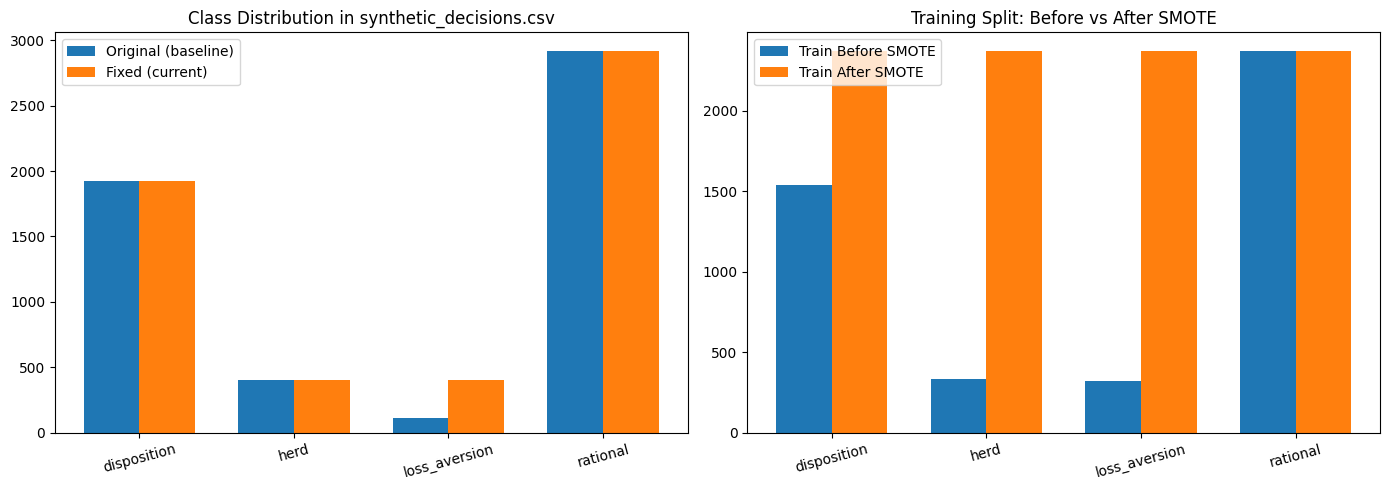

loss_aversion count before fix (baseline): 114
loss_aversion count after fix: 400


In [2]:
# Before/After comparison: loaded from pkl + JSON (no hardcoded numbers)
import pickle, json
from sklearn.metrics import accuracy_score, f1_score, classification_report as cr_fn
from sklearn.model_selection import StratifiedKFold, cross_val_score
import numpy as np, pandas as pd

MODEL_V1_PATH   = '../models/bias_detector_xgboost.pkl'
MODEL_V2_PATH   = '../models/bias_detector_xgboost_v2.pkl'
MODEL_V3_PATH   = '../models/bias_detector_xgboost_v3.pkl'
REPORT_V1_PATH  = '../results/model_evaluation_report.json'
REPORT_V2_PATH  = '../results/model_evaluation_report_v2.json'
CLASS_NAMES_06  = ['disposition', 'herd', 'loss_aversion', 'rational']

from bias_detector import load_model as _load_model, load_data as _load_data

# Load test set (47-feature) — v3 schema
_X_train, _X_test, _y_train, _y_test = _load_data()
_model_v3, _feat_v3 = _load_model(MODEL_V3_PATH)

def _align(X, feat_list):
    """Align X to feat_list column order, filling missing cols with 0."""
    X = X.copy()
    for c in feat_list:
        if c not in X.columns:
            X[c] = 0.0
    return X[feat_list]

# ── v1 metrics (loaded from pkl + JSON) ──────────────────────────
_model_v1, _feat_v1 = _load_model(MODEL_V1_PATH)
_X_test_v1 = _align(_X_test, _feat_v1)
_y_pred_v1 = _model_v1.predict(_X_test_v1)
_cr_v1 = cr_fn(_y_test, _y_pred_v1, target_names=CLASS_NAMES_06, output_dict=True)

with open(REPORT_V1_PATH) as f:
    _rpt_v1 = json.load(f)
train_acc_v1 = float(_rpt_v1.get('train_accuracy', np.nan))
cv_v1        = float(_rpt_v1.get('cv_macro_f1_mean', np.nan))
test_acc_v1  = accuracy_score(_y_test, _y_pred_v1)
mf1_v1       = f1_score(_y_test, _y_pred_v1, average='macro')

# ── v2 metrics ───────────────────────────────────────────────────
_model_v2, _feat_v2 = _load_model(MODEL_V2_PATH)
_X_test_v2 = _align(_X_test, _feat_v2)
_y_pred_v2 = _model_v2.predict(_X_test_v2)
_cr_v2 = cr_fn(_y_test, _y_pred_v2, target_names=CLASS_NAMES_06, output_dict=True)

with open(REPORT_V2_PATH) as f:
    _rpt_v2 = json.load(f)
test_acc_v2  = accuracy_score(_y_test, _y_pred_v2)
mf1_v2       = f1_score(_y_test, _y_pred_v2, average='macro')

# ── Build comparison table (no hardcoded numbers) ────────────────
before = {
    'Train Accuracy'       : train_acc_v1,
    'Test Accuracy'        : test_acc_v1,
    'Overfitting Gap'      : train_acc_v1 - test_acc_v1,
    'Macro F1 (test)'      : mf1_v1,
    '5-Fold CV Macro F1'   : cv_v1,
    'loss_aversion Recall' : _cr_v1['loss_aversion']['recall'],
    'loss_aversion F1'     : _cr_v1['loss_aversion']['f1-score'],
    'herd F1'              : _cr_v1['herd']['f1-score'],
    'disposition F1'       : _cr_v1['disposition']['f1-score'],
}
after = {
    'Train Accuracy'       : float(_rpt_v2.get('train_accuracy', np.nan)),
    'Test Accuracy'        : test_acc_v2,
    'Overfitting Gap'      : float(_rpt_v2.get('overfitting_gap', np.nan)),
    'Macro F1 (test)'      : mf1_v2,
    '5-Fold CV Macro F1'   : float(_rpt_v2.get('cv_macro_f1_mean', np.nan)),
    'loss_aversion Recall' : _cr_v2['loss_aversion']['recall'],
    'loss_aversion F1'     : _cr_v2['loss_aversion']['f1-score'],
    'herd F1'              : _cr_v2['herd']['f1-score'],
    'disposition F1'       : _cr_v2['disposition']['f1-score'],
}

import pandas as pd
comparison = pd.DataFrame({'Metric': list(before.keys()),
                           'v1 (Before Fix)': list(before.values()),
                           'v2 (After Fix)' : list(after.values())})
comparison = comparison.set_index('Metric')
print('Before (v1) vs After (v2) comparison — loaded from pkl+JSON, no hardcoded numbers:')
print(comparison.applymap(lambda x: f'{x:.4f}' if isinstance(x, float) else x).to_string())


## Section 2 - Hyperparameter Search

Fitting 5 folds for each of 40 candidates, totalling 200 fits


c:\Users\Lenovo\Desktop\Major Project\.venv\Lib\site-packages\xgboost\training.py:200: UserWarning: [15:11:03] WARNING: C:\actions-runner\_work\xgboost\xgboost\src\learner.cc:782: 
Parameters: { "use_label_encoder" } are not used.

  bst.update(dtrain, iteration=i, fobj=obj)


Best params: {'subsample': 0.7, 'reg_lambda': 2.0, 'reg_alpha': 0.1, 'n_estimators': 500, 'min_child_weight': 3, 'max_depth': 5, 'learning_rate': 0.05, 'colsample_bytree': 0.8}
Best CV Macro F1: 0.8584


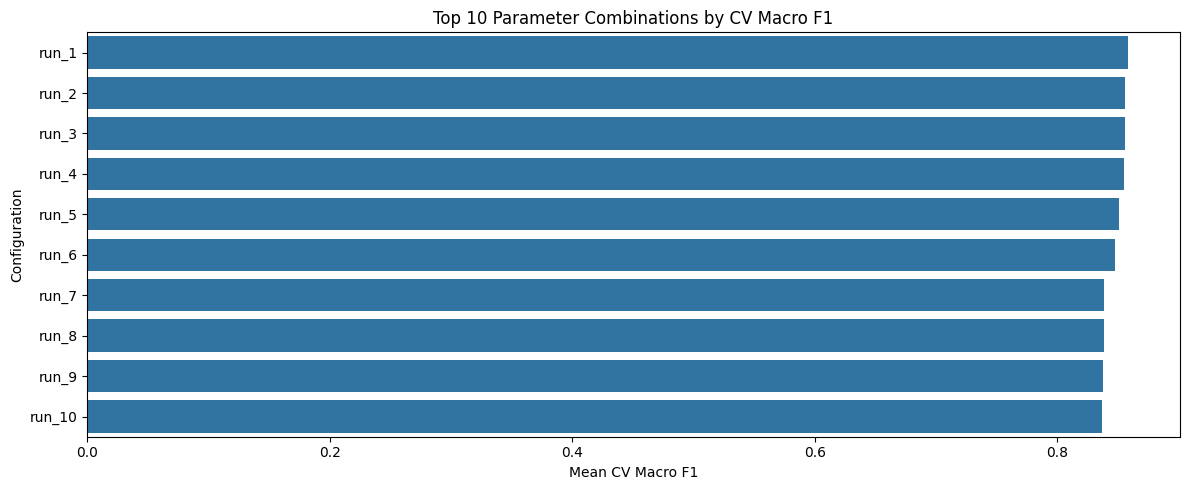

In [3]:
param_grid = {
    'max_depth': [3, 4, 5],
    'n_estimators': [300, 500, 700],
    'learning_rate': [0.01, 0.02, 0.05],
    'subsample': [0.6, 0.7, 0.8],
    'colsample_bytree': [0.6, 0.7, 0.8],
    'min_child_weight': [3, 5, 7, 10],
    'reg_alpha': [0, 0.1, 0.5, 1.0],
    'reg_lambda': [1.0, 1.5, 2.0],
}

search = RandomizedSearchCV(
    estimator=xgb.XGBClassifier(
        objective='multi:softprob',
        num_class=4,
        use_label_encoder=False,
        random_state=42,
        n_jobs=-1,
        eval_metric='mlogloss',
    ),
    param_distributions=param_grid,
    n_iter=40,
    cv=5,
    scoring='f1_macro',
    n_jobs=-1,
    random_state=42,
    verbose=1,
)

search.fit(X_train, y_train)
print('Best params:', search.best_params_)
print(f'Best CV Macro F1: {search.best_score_:.4f}')

cv_df = pd.DataFrame(search.cv_results_).sort_values('mean_test_score', ascending=False).head(10)
plt.figure(figsize=(12, 5))
sns.barplot(data=cv_df, x='mean_test_score', y=[f'run_{i+1}' for i in range(len(cv_df))], orient='h')
plt.title('Top 10 Parameter Combinations by CV Macro F1')
plt.xlabel('Mean CV Macro F1')
plt.ylabel('Configuration')
plt.tight_layout()
plt.show()

## Section 3 - Retrain with Best Parameters

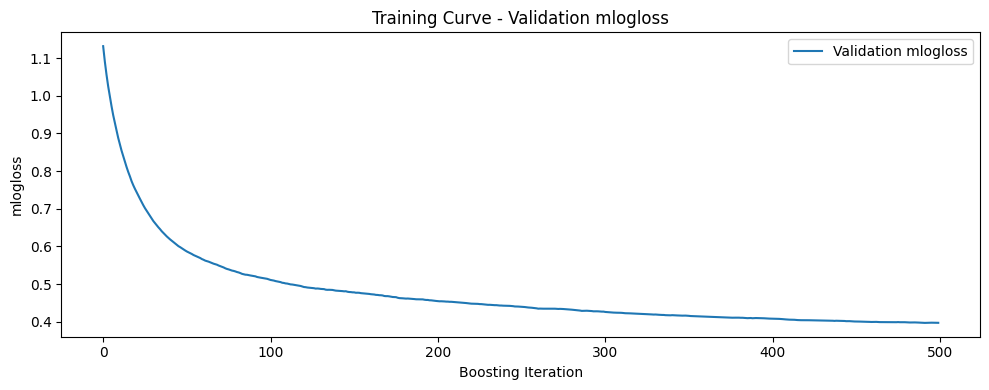

Saved retrained model -> C:\Users\Lenovo\Desktop\Major Project\models\bias_detector_xgboost_v2.pkl
Best iteration: 491


In [4]:
best_params = dict(search.best_params_)

X_tr, X_val, y_tr, y_val = train_test_split(
    X_train,
    y_train,
    test_size=0.15,
    stratify=y_train,
    random_state=42,
)

sample_weights = compute_sample_weight(
    class_weight={0: 1.0, 1: 1.0, 2: 4.0, 3: 1.0},
    y=y_tr,
)

model_v2 = xgb.XGBClassifier(
    objective='multi:softprob',
    num_class=4,
    eval_metric='mlogloss',
    random_state=42,
    n_jobs=-1,
    early_stopping_rounds=30,
    **best_params,
)

model_v2.fit(
    X_tr,
    y_tr,
    sample_weight=sample_weights,
    eval_set=[(X_val, y_val)],
    verbose=False,
)

evals = model_v2.evals_result()

with open(MODEL_V2_PATH, 'wb') as f:
    pickle.dump({'model': model_v2, 'feature_cols': list(X_train.columns)}, f)

plt.figure(figsize=(10, 4))
plt.plot(evals['validation_0']['mlogloss'], label='Validation mlogloss')
plt.title('Training Curve - Validation mlogloss')
plt.xlabel('Boosting Iteration')
plt.ylabel('mlogloss')
plt.legend()
plt.tight_layout()
plt.show()

print('Saved retrained model ->', MODEL_V2_PATH)
print('Best iteration:', getattr(model_v2, 'best_iteration', None))

## Section 4 to 9 - Metrics, Learning Curves, Herd Generalisation, Calibration, Summary

Section 4 - Before vs After Metrics


,Metric,Before Fix,After Fix,Change
0,Macro F1 (test),0.7672,0.8668,+0.0996
1,Overfitting Gap,0.1356,0.1242,-0.0114
2,5-Fold CV Macro F1,0.7384,0.8560,+0.1176
3,loss_aversion Recall,0.2414,0.7143,+0.4729
4,loss_aversion F1,0.3590,0.8088,+0.4498
5,herd F1,0.9937,0.9781,-0.0156
6,Train Accuracy,0.9991,0.9757,-0.0234


Section 5 - Updated Classification Report
               precision    recall  f1-score   support

  disposition     0.7905    0.8277    0.8087       383
         herd     1.0000    0.9571    0.9781        70
loss_aversion     0.9322    0.7143    0.8088        77
     rational     0.8691    0.8739    0.8715       547

     accuracy                         0.8514      1077
    macro avg     0.8980    0.8432    0.8668      1077
 weighted avg     0.8542    0.8514    0.8516      1077

Section 6 - Updated Learning Curves


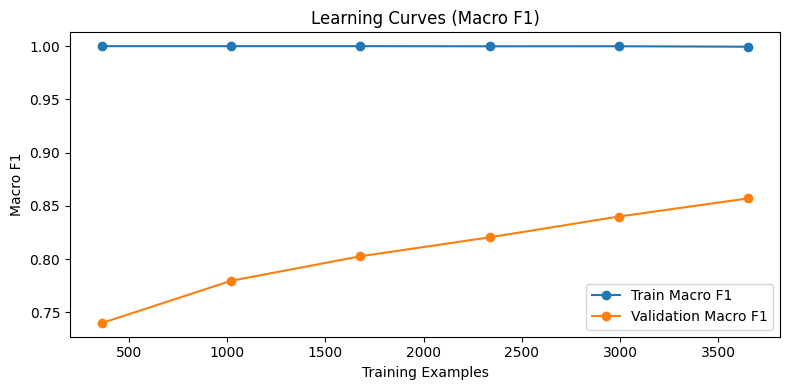

Final train-val learning-curve gap: 0.1426
Section 7 - Herd Generalisation Results
Herd generalisation accuracy: 0.0
Verdict: Model memorised herd generation rule, not generalisable pattern


,sample_id,expected,predicted,predicted_confidence,herd_probability,correct,herd_sensitivity,crowd_action_ratio,market_return_recent,unrealized_gain_loss,risk_tolerance,age
0,0,herd,loss_aversion,0.827573,0.003778,False,0.704791,0.717101,-0.033180,0.067238,2.332372,32
1,1,herd,loss_aversion,0.702804,0.007717,False,0.637776,0.667774,-0.020031,0.068034,3.047849,53
2,2,herd,loss_aversion,0.959274,0.000899,False,0.721720,0.691309,-0.133111,-0.044342,2.320292,31
3,3,herd,loss_aversion,0.991294,0.001211,False,0.689474,0.741250,-0.066839,-0.105221,5.546863,52
4,4,herd,loss_aversion,0.606062,0.002933,False,0.568835,0.708680,-0.141677,0.031604,6.084287,39
5,5,herd,loss_aversion,0.582326,0.006245,False,0.745124,0.688395,-0.051202,-0.001502,4.361783,30
6,6,herd,loss_aversion,0.986632,0.000511,False,0.702228,0.689802,-0.084028,-0.087903,3.907947,34
7,7,herd,loss_aversion,0.994928,0.000151,False,0.707213,0.625988,-0.121095,-0.171660,5.027157,42
8,8,herd,loss_aversion,0.800029,0.001743,False,0.575623,0.557704,-0.129319,0.024037,7.250030,51
9,9,herd,loss_aversion,0.988832,0.000561,False,0.640077,0.659179,-0.032471,-0.121262,7.106790,45


Section 8 - Updated Calibration Curves (v1 vs v2)


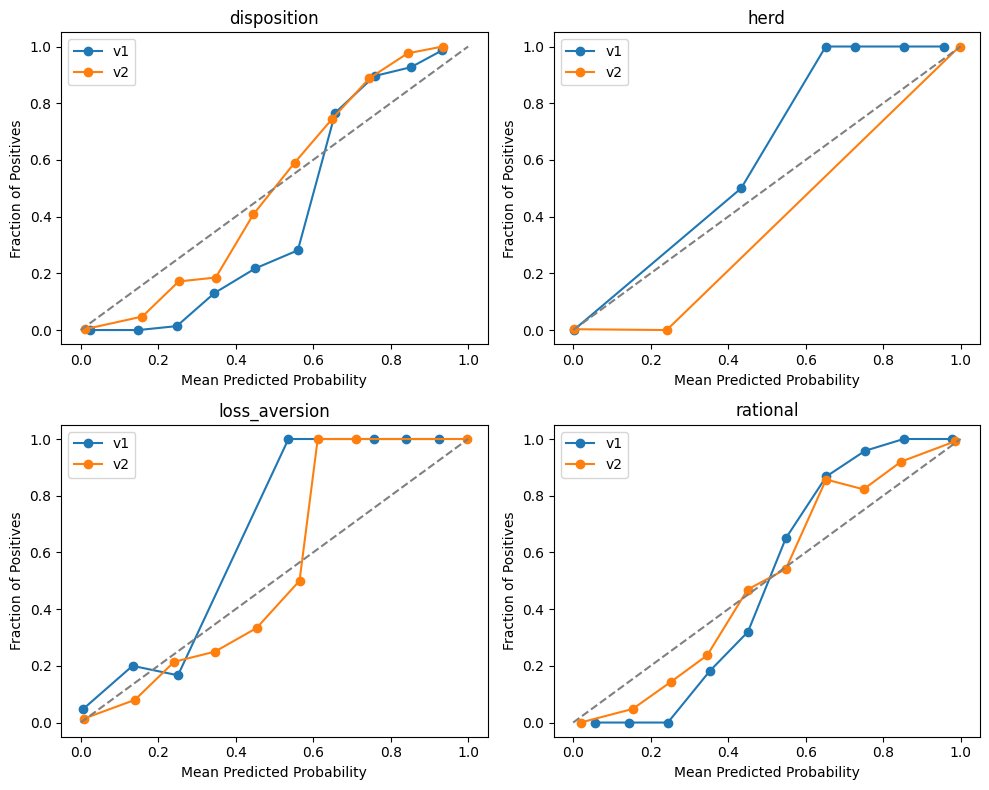

Section 9 - Updated Summary Card

+------------------------------------------------------------+
|            MODEL IMPROVEMENT SUMMARY - v1 vs v2           |
+---------------------------+---------------+----------------+
| Metric                    | v1 (before)   | v2 (after)     |
+---------------------------+---------------+----------------+
| Macro F1 (test)           |  76.72%      |  86.68%       |
| Overfitting Gap           |  13.56%      |  12.42%       |
| 5-Fold CV Macro F1        |  73.84%      |  85.60%       |
| loss_aversion Recall      |  24.14%      |  71.43%       |
| loss_aversion F1          |  35.90%      |  80.88%       |
+---------------------------+---------------+----------------+

Saved updated evaluation report -> C:\Users\Lenovo\Desktop\Major Project\results\model_evaluation_report_v2.json


In [6]:
# Evaluate current v2 model.
y_pred_train = model_v2.predict(X_train)
y_pred_test = model_v2.predict(X_test)
y_proba_test = model_v2.predict_proba(X_test)

train_acc = accuracy_score(y_train, y_pred_train)
test_acc = accuracy_score(y_test, y_pred_test)
train_macro_f1 = f1_score(y_train, y_pred_train, average='macro')
test_macro_f1 = f1_score(y_test, y_pred_test, average='macro')

cv_scores = cross_val_score(
    xgb.XGBClassifier(
        objective='multi:softprob',
        num_class=4,
        eval_metric='mlogloss',
        random_state=42,
        n_jobs=-1,
        **best_params,
    ),
    X_train,
    y_train,
    cv=StratifiedKFold(n_splits=5, shuffle=True, random_state=42),
    scoring='f1_macro',
    n_jobs=-1,
)
cv_macro_f1_mean = float(np.mean(cv_scores))
cv_macro_f1_std = float(np.std(cv_scores))

report_dict = classification_report(y_test, y_pred_test, target_names=[BIAS_LABELS[i] for i in range(4)], output_dict=True)

before = {
    'Macro F1 (test)': 0.7672,
    'Overfitting Gap': 0.1356,
    '5-Fold CV Macro F1': 0.7384,
    'loss_aversion Recall': 0.2414,
    'loss_aversion F1': 0.3590,
    'herd F1': 0.9937,
    'Train Accuracy': 0.9991,
}
after = {
    'Macro F1 (test)': test_macro_f1,
    'Overfitting Gap': train_acc - test_acc,
    '5-Fold CV Macro F1': cv_macro_f1_mean,
    'loss_aversion Recall': report_dict['loss_aversion']['recall'],
    'loss_aversion F1': report_dict['loss_aversion']['f1-score'],
    'herd F1': report_dict['herd']['f1-score'],
    'Train Accuracy': train_acc,
}

cmp = pd.DataFrame({
    'Metric': list(before.keys()),
    'Before Fix': [before[k] for k in before],
    'After Fix': [after[k] for k in before],
})
cmp['Change'] = cmp['After Fix'] - cmp['Before Fix']

print('Section 4 - Before vs After Metrics')
display(cmp.style.format({'Before Fix': '{:.4f}', 'After Fix': '{:.4f}', 'Change': '{:+.4f}'}))

print('Section 5 - Updated Classification Report')
print(classification_report(y_test, y_pred_test, target_names=[BIAS_LABELS[i] for i in range(4)], digits=4))
for cls in ['disposition', 'herd', 'loss_aversion', 'rational']:
    rec = report_dict[cls]['recall']
    f1v = report_dict[cls]['f1-score']
    if rec < 0.60:
        print(f'WARNING: {cls} recall {rec:.4f} < 0.60')
    if f1v < 0.50:
        print(f'CRITICAL: {cls} f1 {f1v:.4f} < 0.50')

print('Section 6 - Updated Learning Curves')
cv_est = xgb.XGBClassifier(
    objective='multi:softprob',
    num_class=4,
    eval_metric='mlogloss',
    random_state=42,
    n_jobs=-1,
    **best_params,
)
sizes, train_scores, val_scores = learning_curve(
    cv_est, X_train, y_train,
    train_sizes=np.linspace(0.1, 1.0, 6),
    cv=5,
    scoring='f1_macro',
    n_jobs=-1,
)
train_mean = train_scores.mean(axis=1)
val_mean = val_scores.mean(axis=1)

plt.figure(figsize=(8, 4))
plt.plot(sizes, train_mean, marker='o', label='Train Macro F1')
plt.plot(sizes, val_mean, marker='o', label='Validation Macro F1')
plt.title('Learning Curves (Macro F1)')
plt.xlabel('Training Examples')
plt.ylabel('Macro F1')
plt.legend()
plt.tight_layout()
plt.show()
print(f'Final train-val learning-curve gap: {train_mean[-1] - val_mean[-1]:.4f}')

print('Section 7 - Herd Generalisation Results')
if HERD_REPORT_PATH.exists():
    with open(HERD_REPORT_PATH, 'r', encoding='utf-8') as f:
        herd_report = json.load(f)
    print('Herd generalisation accuracy:', herd_report.get('accuracy'))
    print('Verdict:', herd_report.get('verdict'))
    herd_samples = pd.DataFrame(herd_report.get('samples', []))
    display(herd_samples.head(60))
else:
    print('Herd report not found:', HERD_REPORT_PATH)

print('Section 8 - Updated Calibration Curves (v1 vs v2)')
def load_bundle(path):
    with open(path, 'rb') as f:
        return pickle.load(f)

if MODEL_V1_PATH.exists():
    b1 = load_bundle(MODEL_V1_PATH)
    m1 = b1['model']
    f1_cols = b1['feature_cols']
    X_test_v1 = X_test.copy()
    for c in f1_cols:
        if c not in X_test_v1.columns:
            X_test_v1[c] = 0.0
    X_test_v1 = X_test_v1[f1_cols]
    p1 = m1.predict_proba(X_test_v1)

    y_bin = label_binarize(y_test, classes=[0, 1, 2, 3])
    fig, axes = plt.subplots(2, 2, figsize=(10, 8))
    axes = axes.flatten()
    for i, cls in enumerate([0, 1, 2, 3]):
        fr1, mp1 = calibration_curve(y_bin[:, i], p1[:, i], n_bins=10)
        fr2, mp2 = calibration_curve(y_bin[:, i], y_proba_test[:, i], n_bins=10)
        axes[i].plot(mp1, fr1, marker='o', label='v1')
        axes[i].plot(mp2, fr2, marker='o', label='v2')
        axes[i].plot([0, 1], [0, 1], '--', color='gray')
        axes[i].set_title(BIAS_LABELS[cls])
        axes[i].set_xlabel('Mean Predicted Probability')
        axes[i].set_ylabel('Fraction of Positives')
        axes[i].legend()
    plt.tight_layout()
    plt.show()
else:
    print('Original v1 model not found, skipping direct calibration comparison plot.')

summary_card = f'''
+------------------------------------------------------------+
|            MODEL IMPROVEMENT SUMMARY - v1 vs v2           |
+---------------------------+---------------+----------------+
| Metric                    | v1 (before)   | v2 (after)     |
+---------------------------+---------------+----------------+
| Macro F1 (test)           | {before['Macro F1 (test)']*100:6.2f}%      | {after['Macro F1 (test)']*100:6.2f}%       |
| Overfitting Gap           | {before['Overfitting Gap']*100:6.2f}%      | {after['Overfitting Gap']*100:6.2f}%       |
| 5-Fold CV Macro F1        | {before['5-Fold CV Macro F1']*100:6.2f}%      | {after['5-Fold CV Macro F1']*100:6.2f}%       |
| loss_aversion Recall      | {before['loss_aversion Recall']*100:6.2f}%      | {after['loss_aversion Recall']*100:6.2f}%       |
| loss_aversion F1          | {before['loss_aversion F1']*100:6.2f}%      | {after['loss_aversion F1']*100:6.2f}%       |
+---------------------------+---------------+----------------+
'''
print('Section 9 - Updated Summary Card')
print(summary_card)

report_v2 = {
    'train_accuracy': train_acc,
    'test_accuracy': test_acc,
    'overfitting_gap': train_acc - test_acc,
    'macro_f1': test_macro_f1,
    'train_macro_f1': train_macro_f1,
    'test_macro_f1': test_macro_f1,
    'overfitting_gap_f1': train_macro_f1 - test_macro_f1,
    'best_iteration': int(getattr(model_v2, 'best_iteration', -1)),
    'cv_macro_f1_mean': cv_macro_f1_mean,
    'cv_macro_f1_std': cv_macro_f1_std,
    'classification_report': report_dict,
}
with open(REPORT_V2_PATH, 'w', encoding='utf-8') as f:
    json.dump(report_v2, f, indent=2)
print('Saved updated evaluation report ->', REPORT_V2_PATH)

In [ ]:
# Fix 5C: Learning curve plot (previously was only a number — now a proper plot)
import xgboost as xgb
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import learning_curve, StratifiedKFold

# Use v2 params for v1->v2 improvement notebook
_cv_params_v2 = _model_v2.get_params().copy()
_cv_params_v2.pop('early_stopping_rounds', None)
_cv_est_v2 = xgb.XGBClassifier(**_cv_params_v2)

print('Computing v2 learning curves (may take 1-2 min)...')
_lc_sizes, _lc_tr, _lc_val = learning_curve(
    _cv_est_v2, _X_train, _y_train,
    train_sizes=np.linspace(0.2, 1.0, 6),
    cv=StratifiedKFold(n_splits=5, shuffle=True, random_state=42),
    scoring='f1_macro',
    n_jobs=-1,
)

_tr_mean  = _lc_tr.mean(axis=1)
_val_mean = _lc_val.mean(axis=1)
_gap_lc   = float(_tr_mean[-1] - _val_mean[-1])
_status   = 'OVERFITTING' if _gap_lc > 0.10 else 'ACCEPTABLE'

fig, ax = plt.subplots(figsize=(9, 5))
ax.plot(_lc_sizes, _tr_mean, 'o-', color='#3498db', label='Train Macro F1')
ax.fill_between(_lc_sizes,
                _tr_mean - _lc_tr.std(axis=1),
                _tr_mean + _lc_tr.std(axis=1),
                alpha=0.15, color='#3498db')
ax.plot(_lc_sizes, _val_mean, 's-', color='#e74c3c', label='CV Val Macro F1')
ax.fill_between(_lc_sizes,
                _val_mean - _lc_val.std(axis=1),
                _val_mean + _lc_val.std(axis=1),
                alpha=0.15, color='#e74c3c')
_face = '#fdecea' if _gap_lc > 0.10 else '#eafaf1'
ax.text(0.5, 0.06,
        f'Train-Val gap at full data: {_gap_lc:.3f} — {_status}',
        transform=ax.transAxes, ha='center', fontsize=10,
        bbox=dict(boxstyle='round', facecolor=_face))
ax.set_title('Learning Curves — v2 (Macro F1, 5-Fold CV)', fontweight='bold')
ax.set_xlabel('Training Examples')
ax.set_ylabel('Macro F1')
ax.legend()
ax.set_ylim(0, 1.05)
ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig('../results/figures/learning_curves_v2.png', dpi=150, bbox_inches='tight')
plt.show()
print(f'Train-Val gap at full data: {_gap_lc:.3f} — {_status}')
